<a href="https://colab.research.google.com/github/Menjadianjay/Time-Series-Code/blob/Feature%2F5_Tugas_5_UTS/LSTM_225314118.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

LSTM Menggunakan Data Saham

______________________________  
Nama : Joseph Seri Aprillio De Ornay  
NIM  : 225314118  
_______________________________  
Tahapan tugas :  
* Mengambil data keuangan dari yahoo finance dengan kode perusahaan yang dituju.  
* Mengambil data historis selama periode waktu tertentu.  
* Melakukan preprocessing data.
* Membagi data menjadi train dan test.   
* Melakukan prediksi dengan metode tuning hyperparameter dan tampilkan perbedaannya
* Terapkan metode sliding window untuk mengatur hyperparameter terbaik
* Melakukan evaluasi dari hasil model tuning hyperparameter dan metode sliding window.  



In [ ]:
import yfinance as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

Memasukan library yang diperlukan untuk mengambil data historis keuangan, mengolah data tabular, melakukan operasi matematika, membuat plot, normalisasi data, mengukur kesalahan prediksi, membagi data menjadi train dan test, dan melakukan proses model.

In [ ]:
saham = tf.Ticker('BBCA.JK')
fullinfo = saham.get_info()
print(fullinfo['longName'])

PT Bank Central Asia Tbk


Mengambil data historis saham BCA dengan menggunakan simbol saham BCA yakni BBCA.JK. Hasil dari nama perusahaan yang digunakan akan tercetak.

In [ ]:
historical_data = saham.history(period="3y")
df = pd.DataFrame(historical_data)
df = df.reset_index()
df.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2022-05-30 00:00:00+07:00,6947.230469,6970.158622,6855.517855,6947.230469,105411400,0.0,0.0
1,2022-05-31 00:00:00+07:00,6970.158140,7107.727051,6901.373685,7107.727051,286292700,0.0,0.0
2,2022-06-02 00:00:00+07:00,6993.086775,7038.943082,6901.374162,6947.230469,149226300,0.0,0.0
3,2022-06-03 00:00:00+07:00,6970.158203,7038.942659,6947.230051,6970.158203,80563100,0.0,0.0
4,2022-06-06 00:00:00+07:00,6924.301964,6947.230116,6809.661203,6832.589355,81140300,0.0,0.0


Mengambil data saham sepanjang 3 tahun terakhir, mengubah menjadi format data frame, dan menempatkan date sebagai salah satu kolom dengan menggunakan reset index. Kemudian menampilkan 5 baris awal dari data untuk melihat hasil dari reset index, dan keadaan data secara sekilas (format penulisan date, open hingga stock_splits) Hal ini menentukan pada step selanjutnya data harus dikonversi menjadi tipe data atau format lainnya atau tidak.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype                       
---  ------        --------------  -----                       
 0   Date          720 non-null    datetime64[ns, Asia/Jakarta]
 1   Open          720 non-null    float64                     
 2   High          720 non-null    float64                     
 3   Low           720 non-null    float64                     
 4   Close         720 non-null    float64                     
 5   Volume        720 non-null    int64                       
 6   Dividends     720 non-null    float64                     
 7   Stock Splits  720 non-null    float64                     
dtypes: datetime64[ns, Asia/Jakarta](1), float64(6), int64(1)
memory usage: 45.1 KB


Melihat informasi data sehingga dapat diamati bahwa data tidak memiliki nilai null, dan memiliki tipe data yang sudah dikehendaki. Bagian ini adalah validasi dari hasil sekilas yang sudah dilihat pada head dataframe.

In [ ]:
scaler = MinMaxScaler(feature_range=(0,1))
data = scaler.fit_transform(df[['Close']])
scaled_data=data

Normalisasi data menjadi data dengan jangkauan 0 hingga 1 dan menempatkan hasil dari normalisasi data pada data yang dipilih yakni kolom close price.

In [ ]:
window_size = 10
X = []
y = []
target_dates = df.index[window_size:]

for i in range(window_size, len(data)):
    X.append(data[i - window_size:i, 0])
    y.append(data[i, 0])

X = np.array(X)
y = np.array(y)

X_train, X_test, y_train, y_test, dates_train, dates_test = train_test_split(
    X, y, target_dates, test_size=0.2, shuffle=False
)

X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

print(f"Shape dari X_train:{X_train.shape}")
print(f"Shape dari X_test:{X_test.shape}")
print(f"Jumlah data latih: {len(X_train)}")
print(f"Jumlah data test: {len(X_test)}")

Shape dari X_train:(568, 10, 1)
Shape dari X_test:(142, 10, 1)
Jumlah data latih: 568
Jumlah data test: 142


* Menggunakan teknik sliding window agar dapat menerapkan prediksi LSTM, hal ini dikarenakan model ini memerlukan data yang terurut dan banyak set data dalam sebuah latihan sehingga model dapat lebih banyak belajar mengenai pola yang muncul.
* Memisahkan data menjadi data train dan test untuk melihat model dapat belajar dengan baik atau sebaliknya.
* Mencetak hasil shape dari train dan test kemudian jumlah data latih dan test untuk mengetahui jumlah dari data train dan test.

In [ ]:
def plot_hasil(predictions, y_test_original_scale):
  plt.figure(figsize=(12, 6))
  plt.plot(dates_test, y_test_original_scale, label='Actual Close')
  plt.plot(dates_test, predictions, label='Predicted Close')
  plt.title('Actual vs Predicted Close Price Stock BCA')
  plt.xlabel('Date')
  plt.ylabel('Close Price (Rp)')
  plt.legend()
  plt.show()

In [ ]:
def model_prediksi(model, X_train, y_train, X_test, y_test, scaler, dates_test, epochs, batch_size):
  predictions = model.predict(X_test)
  predictions = scaler.inverse_transform(predictions).flatten()
  y_test_original_scale = scaler.inverse_transform(y_test.reshape(-1,1)).flatten()
  rmse = np.sqrt(np.mean((y_test_original_scale - predictions)**2))
  print(f'RMSE: {rmse:.2f}')
  plot_hasil(predictions, y_test_original_scale)

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 71ms/step - loss: 0.1075 - val_loss: 0.0784
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0128 - val_loss: 0.0207
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0049 - val_loss: 0.0031
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 0.0032 - val_loss: 0.0018
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0029 - val_loss: 0.0025
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0026 - val_loss: 0.0029
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0025 - val_loss: 0.0020
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.0022 - val_loss: 0.0021
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0023 - val_loss: 0.0017
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0028 - val_loss: 0.0024
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 148ms/step
RMSE: 244.18


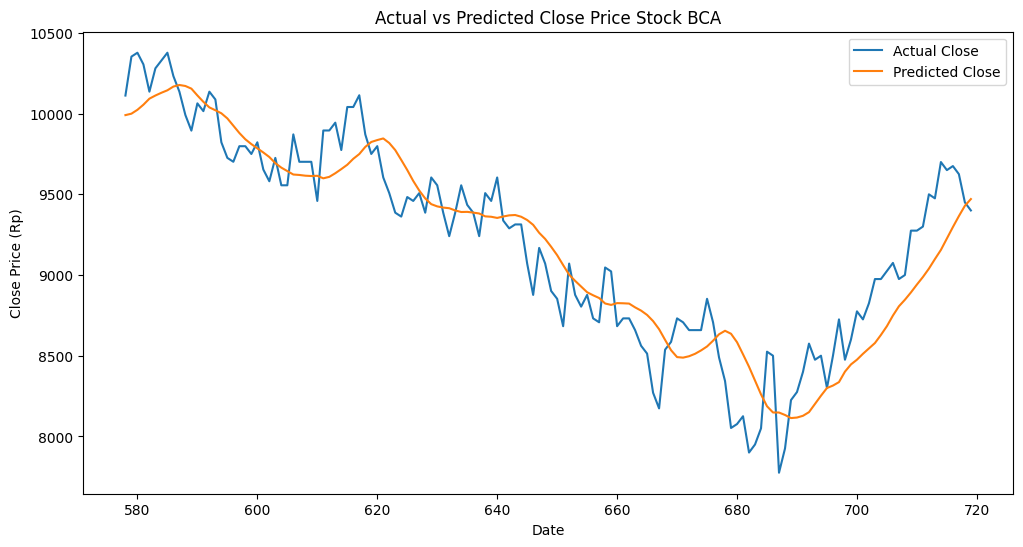

In [ ]:
model = Sequential()
model.add(LSTM(units=128, return_sequences=True, input_shape=(X_train.shape[1], 1)))
model.add(Dropout(0.2))
model.add(LSTM(units=128))
model.add(Dropout(0.2))
model.add(Dense(1))

model.compile(optimizer='adam', loss='mean_squared_error')

history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.1)


scaler.fit(df[['Close']])

model_prediksi(model, X_train, y_train, X_test, y_test, scaler, dates_test, epochs=10, batch_size=32)

Grafik menjelaskan hasil prediksi(jingga) dan data asli(biru) dengan hasil pada grafik dimana garis prediksi mendekati dan hampir menyamai keadaan garis biru menandakan prediksi dapat dikatakan mendekati data aktual. Tetapi prediksi belum dapat dikatakan sangat mendekati karena tidak menangkap votalitas tinggi yang terjadi pada data aktual yang mana banyak naikan dan turunan yang tajam. Walaupun votalitas dari data aktual belum dapat ditangkap dengan baik oleh prediksi tetapi hasil prediksi dapat menangkap arah dari data aktual sehingga mampu mengikuti penurunan dan kenaikan pada titik yang sesuai dengam data aktual.

Hal ini mungkin dipengaruhi juga karena menggunakan metode sliding window yang memprediksi dari data yang dibagi menjadi beberapa bagian sehingga data tidak mengikuti votalitas secara detail namun tetap menangkap arah dari data aktual dengan baik.

In [ ]:
params = {
    'units': [128,150,170],
    'dropout': [0.2,0.3,0.1],
    'epochs': [10,30,20]
}

units: 128
dropout: 0.2
epochs: 10
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 130ms/step - loss: 0.1032 - val_loss: 0.0679
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 81ms/step - loss: 0.0109 - val_loss: 0.0196
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 0.0046 - val_loss: 0.0059
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0032 - val_loss: 0.0019
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.0028 - val_loss: 0.0018
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0023 - val_loss: 0.0022
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0024 - val_loss: 0.0024
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 0.0027 - val_loss: 0.0018
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.0027 - val_loss: 0.0018
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0022 - val_loss: 0.0019
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 130ms/step
RMSE: 246.45


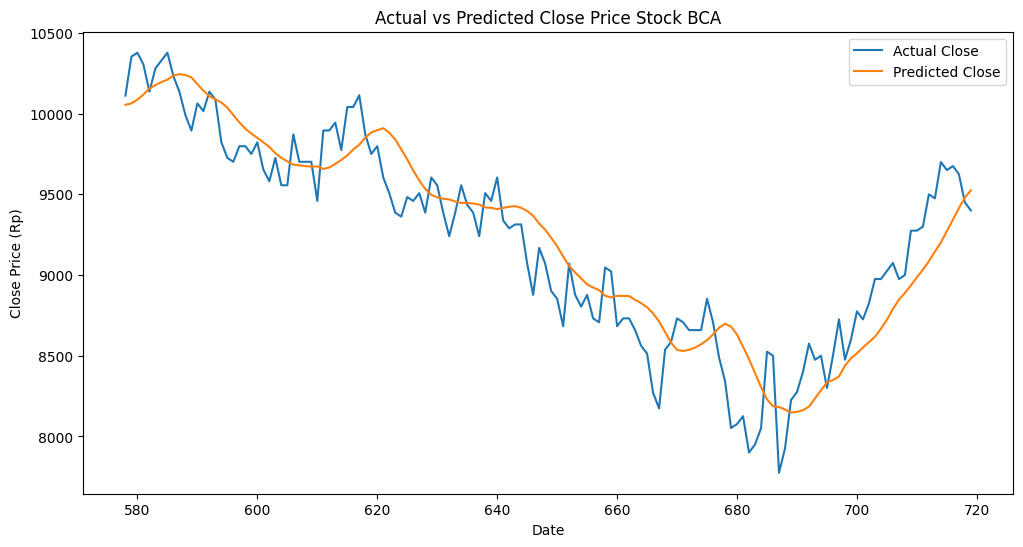

epochs: 30


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 71ms/step - loss: 0.0925 - val_loss: 0.0665
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.0108 - val_loss: 0.0232
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0047 - val_loss: 0.0028
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0032 - val_loss: 0.0019
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 0.0030 - val_loss: 0.0020
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0026 - val_loss: 0.0032
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0024 - val_loss: 0.0033
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 0.0029 - val_loss: 0.0018
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - loss: 0.0025 - val_loss: 0.0019
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - loss: 0.0028 - val_loss: 0.0018
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 144ms/step
RMSE: 262.62


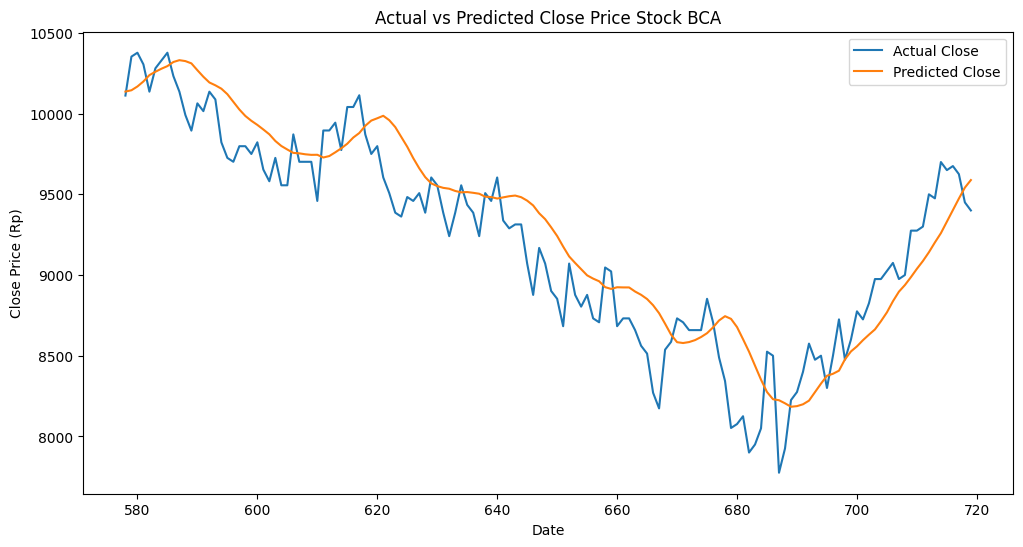

epochs: 20


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step - loss: 0.1001 - val_loss: 0.0609
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0079 - val_loss: 0.0129
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0038 - val_loss: 0.0051
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0032 - val_loss: 0.0039
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0029 - val_loss: 0.0026
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0027 - val_loss: 0.0019
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0022 - val_loss: 0.0017
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0024 - val_loss: 0.0020
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 0.0021 - val_loss: 0.0022
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 76ms/step - loss: 0.0024 - val_loss: 0.0022
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 130ms/step
RMSE: 242.38


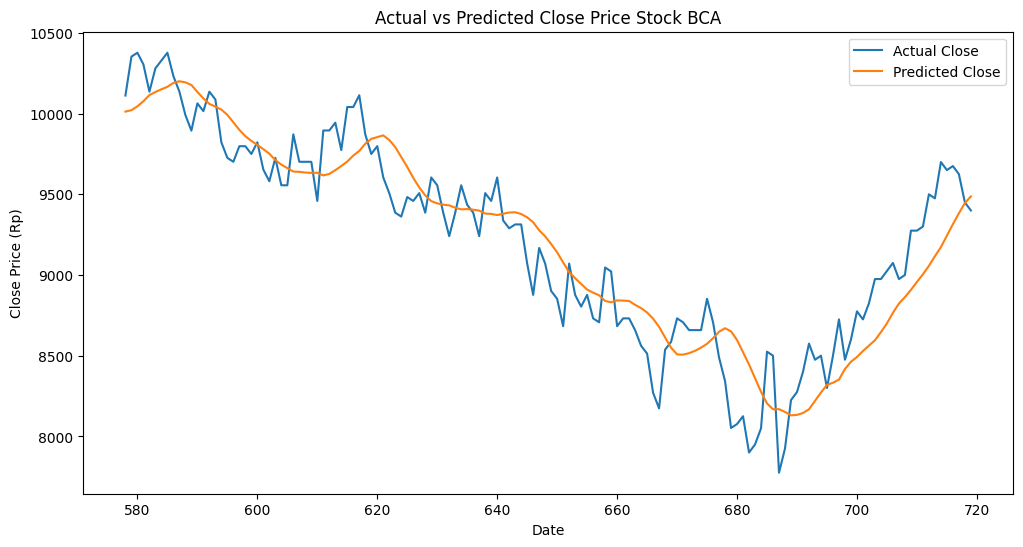

dropout: 0.3
epochs: 10
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step - loss: 0.0982 - val_loss: 0.0537
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0085 - val_loss: 0.0206
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0045 - val_loss: 0.0044
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0030 - val_loss: 0.0030
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 0.0022 - val_loss: 0.0025
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0028 - val_loss: 0.0018
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step - loss: 0.0027 - val_loss: 0.0018
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 77ms/step - loss: 0.0025 - val_loss: 0.0018
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0025 - val_loss: 0.0018
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0023 - val_loss: 0.0025
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step
RMSE: 246.46


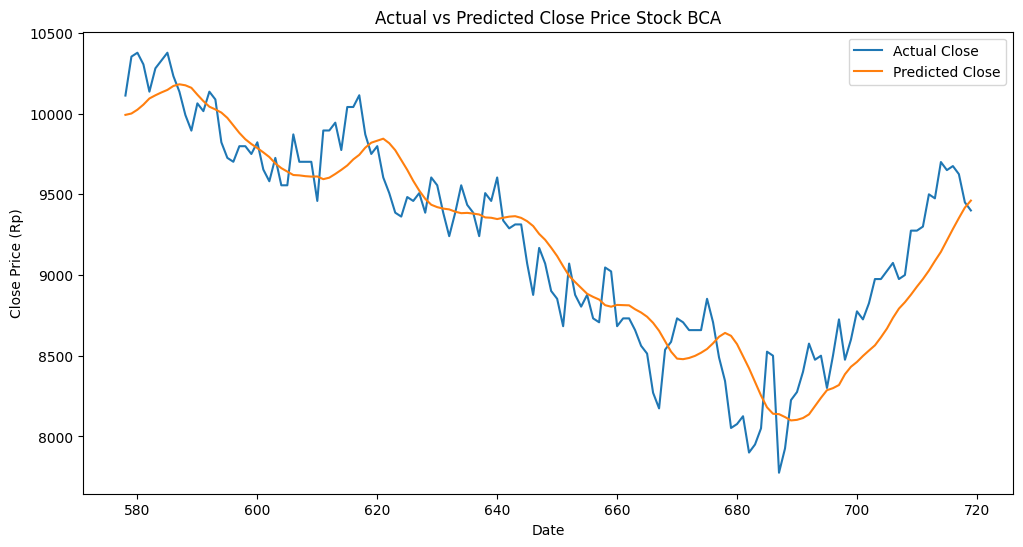

epochs: 30
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 76ms/step - loss: 0.0957 - val_loss: 0.0737
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - loss: 0.0117 - val_loss: 0.0119
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - loss: 0.0038 - val_loss: 0.0041
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - loss: 0.0031 - val_loss: 0.0042
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - loss: 0.0029 - val_loss: 0.0033
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0023 - val_loss: 0.0019
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0024 - val_loss: 0.0018
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0026 - val_loss: 0.0018
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0023 - val_loss: 0.0023
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0023 - val_loss: 0.0024
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step
RMSE: 245.70


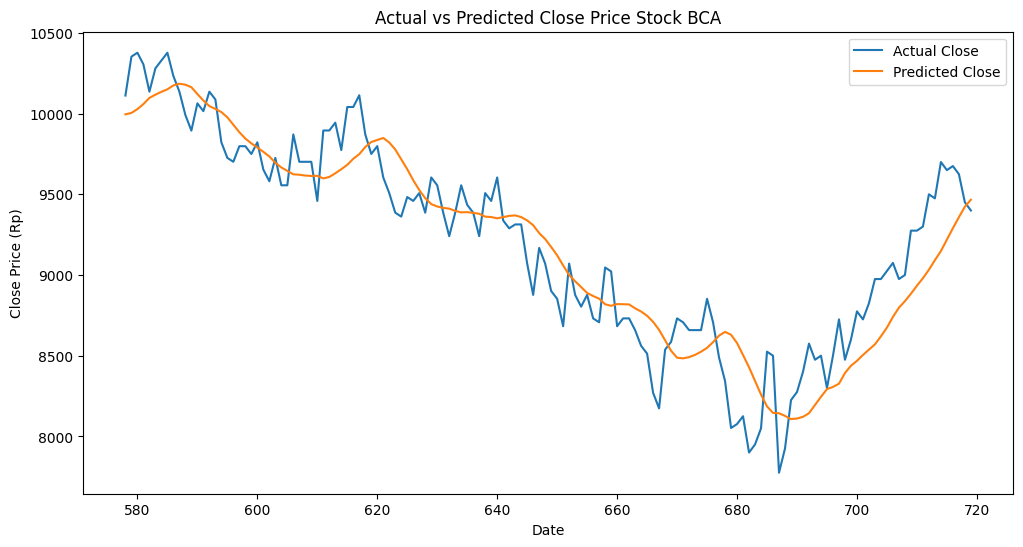

epochs: 20
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 127ms/step - loss: 0.0899 - val_loss: 0.0652
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - loss: 0.0095 - val_loss: 0.0181
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 0.0042 - val_loss: 0.0039
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0033 - val_loss: 0.0024
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0026 - val_loss: 0.0032
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0022 - val_loss: 0.0021
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0026 - val_loss: 0.0018
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - loss: 0.0024 - val_loss: 0.0027
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0025 - val_loss: 0.0022
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0030 - val_loss: 0.0038
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step
RMSE: 257.27


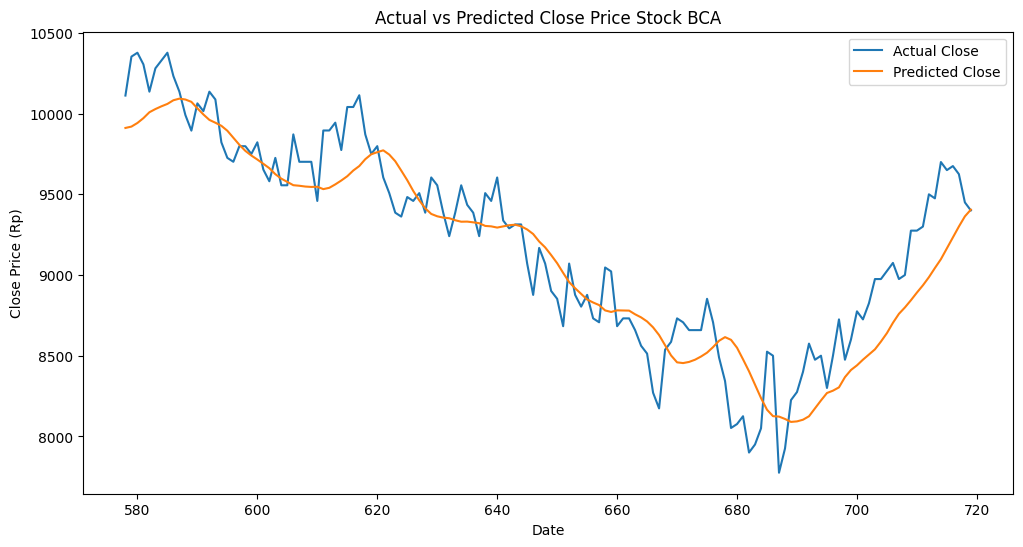

dropout: 0.1
epochs: 10
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 73ms/step - loss: 0.1144 - val_loss: 0.0665
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0091 - val_loss: 0.0076
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0037 - val_loss: 0.0026
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0028 - val_loss: 0.0025
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0031 - val_loss: 0.0028
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0030 - val_loss: 0.0020
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0027 - val_loss: 0.0021
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - loss: 0.0027 - val_loss: 0.0019
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 81ms/step - loss: 0.0025 - val_loss: 0.0019
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.0023 - val_loss: 0.0025
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step
RMSE: 246.87


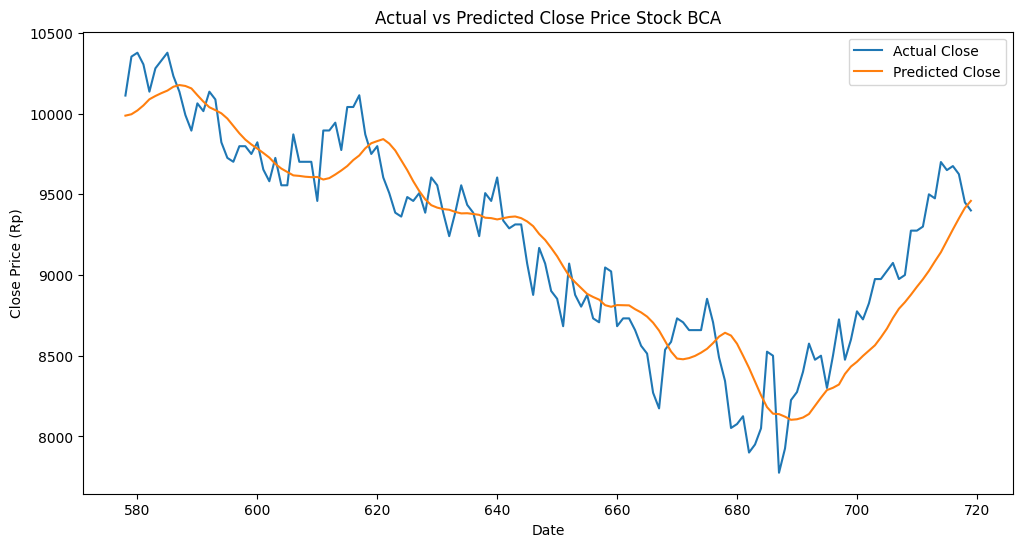

epochs: 30
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step - loss: 0.0845 - val_loss: 0.0503
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0080 - val_loss: 0.0216
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0042 - val_loss: 0.0054
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0029 - val_loss: 0.0029
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - loss: 0.0026 - val_loss: 0.0019
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step - loss: 0.0027 - val_loss: 0.0018
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 0.0025 - val_loss: 0.0019
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0022 - val_loss: 0.0025
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0029 - val_loss: 0.0019
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0026 - val_loss: 0.0021
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step
RMSE: 244.10


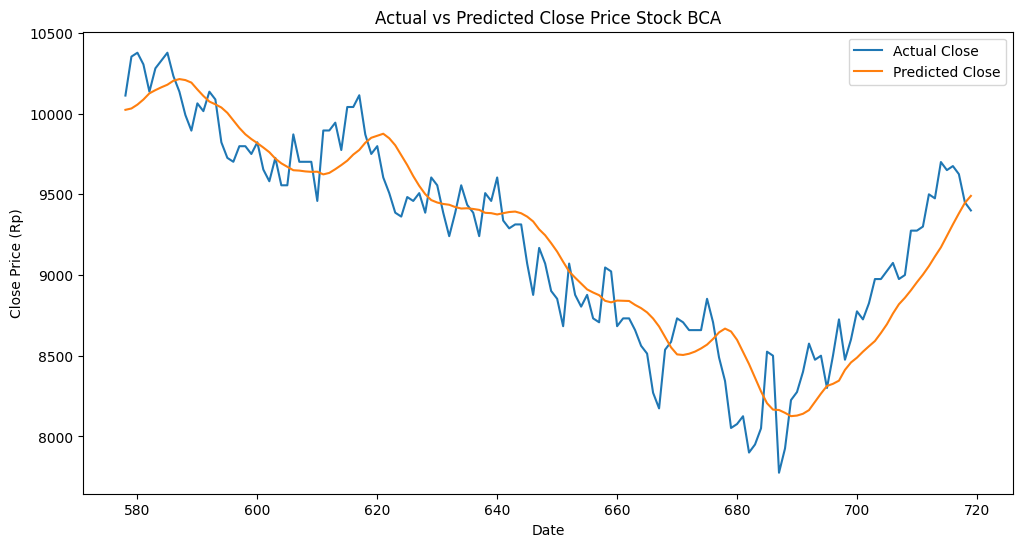

epochs: 20
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 84ms/step - loss: 0.0831 - val_loss: 0.0419
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step - loss: 0.0060 - val_loss: 0.0180
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - loss: 0.0037 - val_loss: 0.0048
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0025 - val_loss: 0.0029
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0026 - val_loss: 0.0027
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0028 - val_loss: 0.0018
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0024 - val_loss: 0.0018
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0027 - val_loss: 0.0058
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0027 - val_loss: 0.0027
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0027 - val_loss: 0.0020
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step
RMSE: 244.25


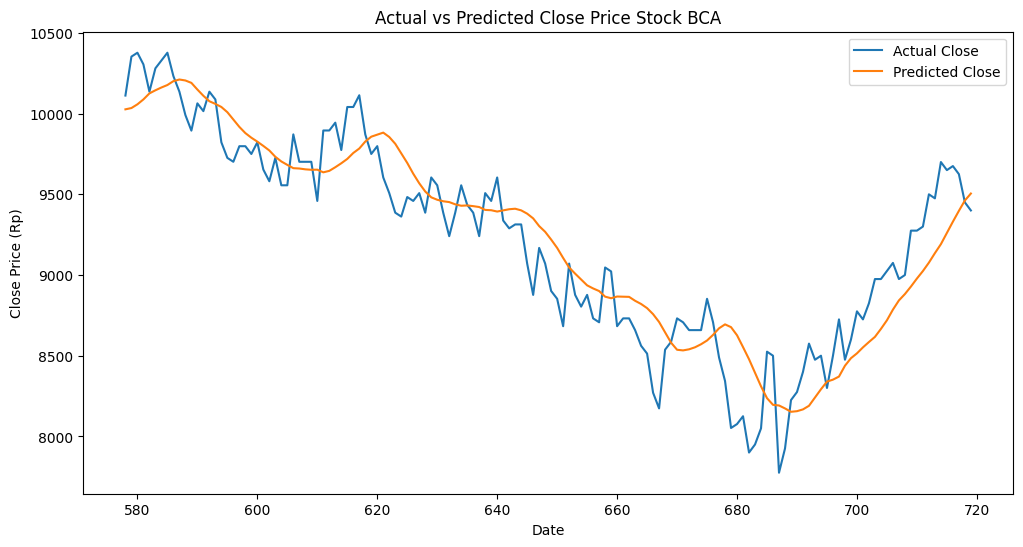

units: 150
dropout: 0.2
epochs: 10
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 119ms/step - loss: 0.1048 - val_loss: 0.0660
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0106 - val_loss: 0.0178
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0043 - val_loss: 0.0062
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0029 - val_loss: 0.0027
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0028 - val_loss: 0.0022
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.0024 - val_loss: 0.0018
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0027 - val_loss: 0.0017
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0022 - val_loss: 0.0017
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0020 - val_loss: 0.0017
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step - loss: 0.0027 - val_loss: 0.0017
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 139ms/step
RMSE: 253.55


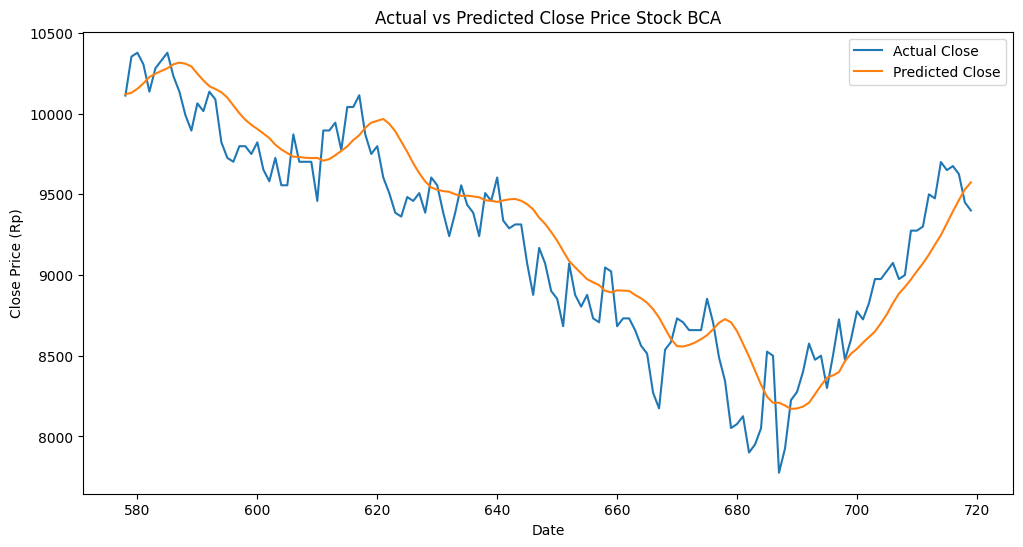

epochs: 30
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 80ms/step - loss: 0.0912 - val_loss: 0.0468
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - loss: 0.0074 - val_loss: 0.0194
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - loss: 0.0040 - val_loss: 0.0071
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step - loss: 0.0034 - val_loss: 0.0033
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - loss: 0.0024 - val_loss: 0.0023
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - loss: 0.0023 - val_loss: 0.0025
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.0026 - val_loss: 0.0018
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.0024 - val_loss: 0.0019
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.0025 - val_loss: 0.0019
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0025 - val_loss: 0.0019
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step
RMSE: 248.90


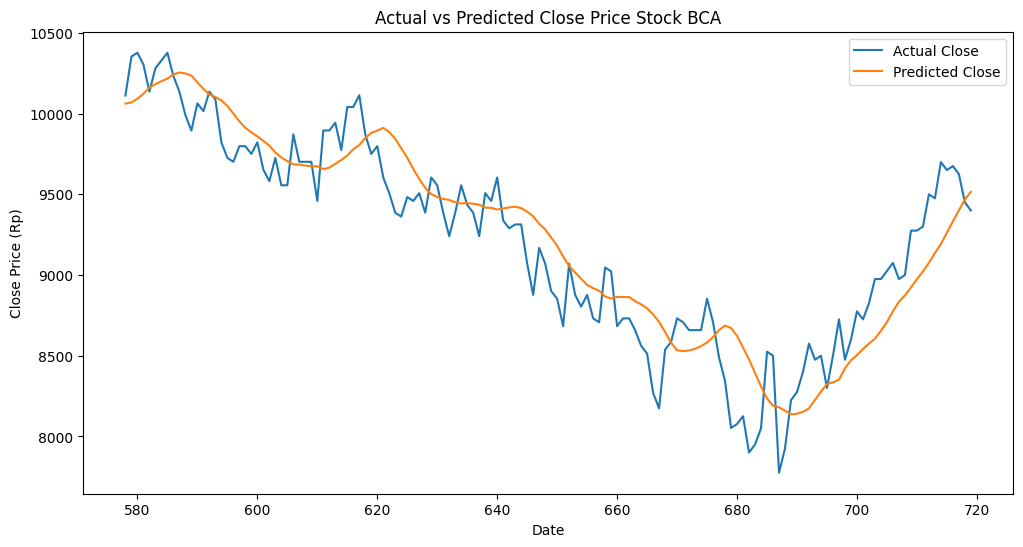

epochs: 20
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 120ms/step - loss: 0.0938 - val_loss: 0.0621
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 87ms/step - loss: 0.0079 - val_loss: 0.0123
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - loss: 0.0043 - val_loss: 0.0064
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - loss: 0.0037 - val_loss: 0.0034
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - loss: 0.0026 - val_loss: 0.0034
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 0.0024 - val_loss: 0.0020
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - loss: 0.0027 - val_loss: 0.0020
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 0.0032 - val_loss: 0.0018
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - loss: 0.0023 - val_loss: 0.0018
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.0026 - val_loss: 0.0018
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step
RMSE: 258.19


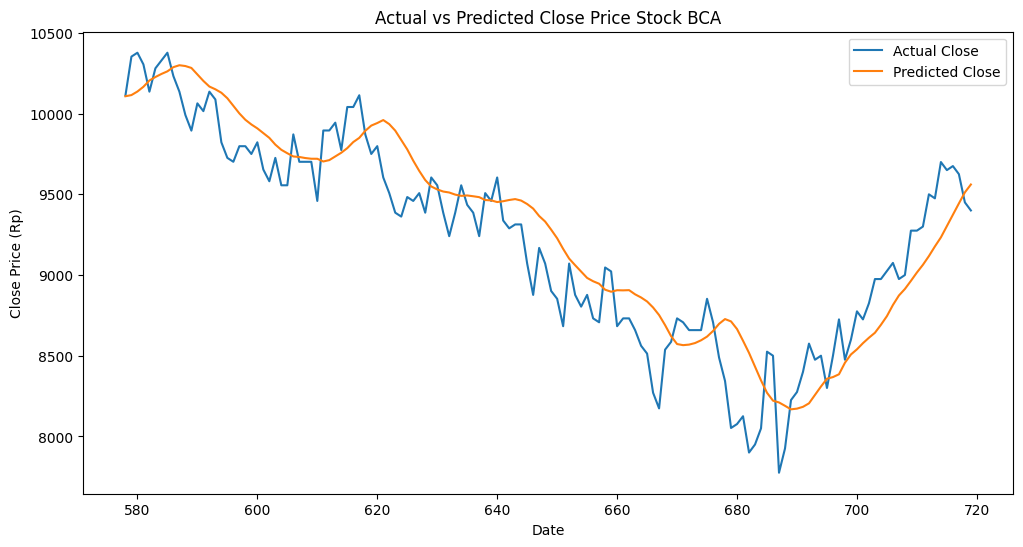

dropout: 0.3
epochs: 10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 78ms/step - loss: 0.0878 - val_loss: 0.0583
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 0.0085 - val_loss: 0.0197
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - loss: 0.0044 - val_loss: 0.0052
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 0.0032 - val_loss: 0.0022
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 0.0024 - val_loss: 0.0027
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0029 - val_loss: 0.0035
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0028 - val_loss: 0.0017
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - loss: 0.0026 - val_loss: 0.0019
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0025 - val_loss: 0.0018
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - loss: 0.0024 - val_loss: 0.0035
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 147ms/step
RMSE: 256.68


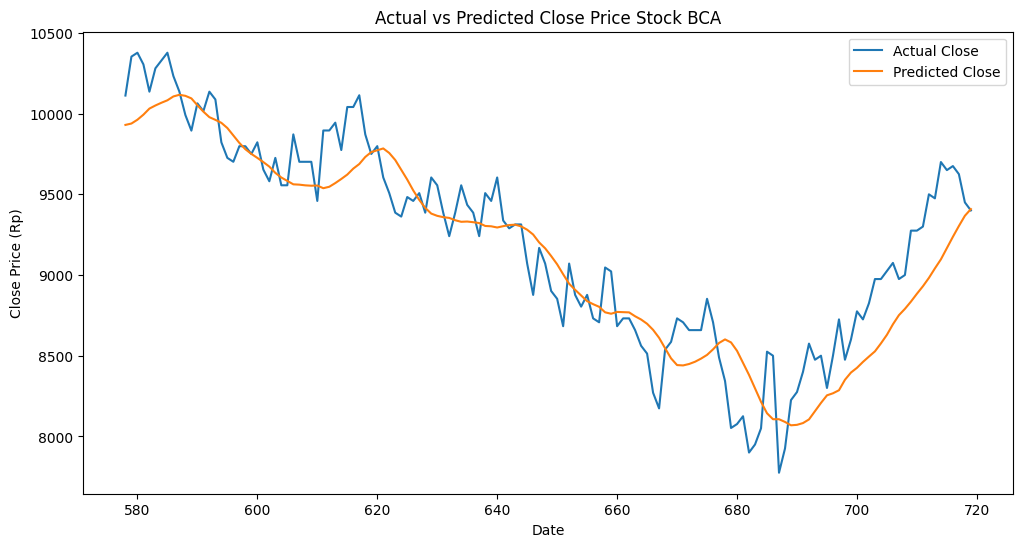

epochs: 30
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 76ms/step - loss: 0.1047 - val_loss: 0.0771
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.0121 - val_loss: 0.0123
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - loss: 0.0040 - val_loss: 0.0035
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.0030 - val_loss: 0.0025
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.0026 - val_loss: 0.0020
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 0.0027 - val_loss: 0.0021
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 0.0025 - val_loss: 0.0021
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - loss: 0.0030 - val_loss: 0.0024
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - loss: 0.0024 - val_loss: 0.0018
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.0025 - val_loss: 0.0017
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step
RMSE: 255.40


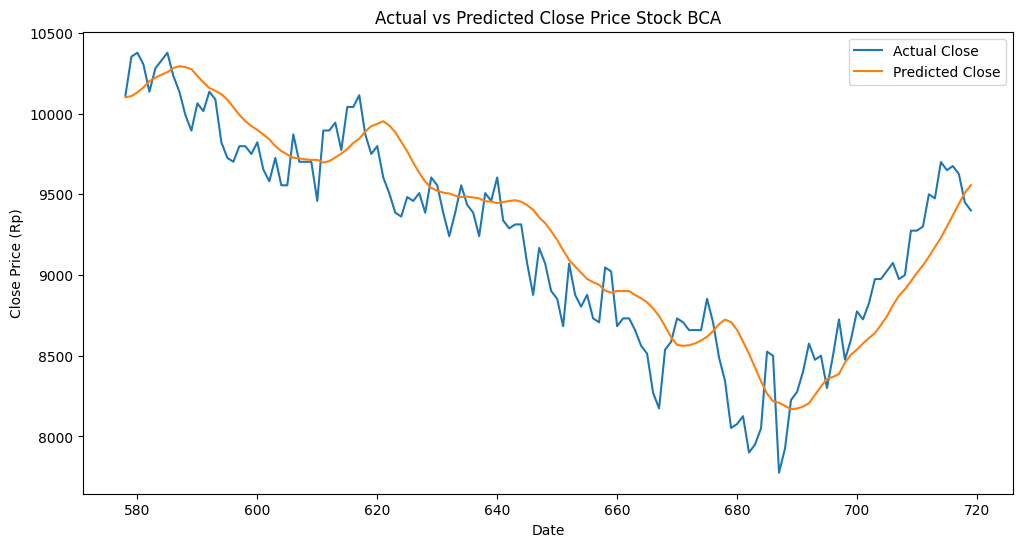

epochs: 20
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 94ms/step - loss: 0.0991 - val_loss: 0.0797
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.0111 - val_loss: 0.0150
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 86ms/step - loss: 0.0047 - val_loss: 0.0043
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - loss: 0.0028 - val_loss: 0.0019
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step - loss: 0.0023 - val_loss: 0.0019
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - loss: 0.0028 - val_loss: 0.0018
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.0028 - val_loss: 0.0025
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 0.0023 - val_loss: 0.0018
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0026 - val_loss: 0.0017
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0023 - val_loss: 0.0026
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step
RMSE: 246.86


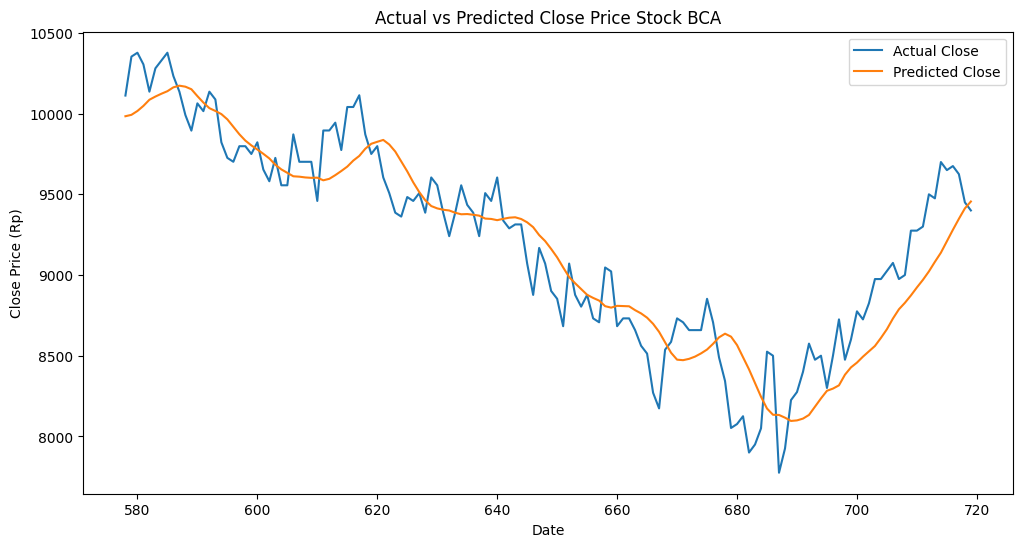

dropout: 0.1
epochs: 10
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 99ms/step - loss: 0.1068 - val_loss: 0.0661
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - loss: 0.0108 - val_loss: 0.0199
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.0051 - val_loss: 0.0064
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - loss: 0.0035 - val_loss: 0.0026
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - loss: 0.0028 - val_loss: 0.0020
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 0.0027 - val_loss: 0.0018
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 0.0024 - val_loss: 0.0021
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 0.0026 - val_loss: 0.0031
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - loss: 0.0024 - val_loss: 0.0018
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.0023 - val_loss: 0.0017
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step
RMSE: 253.33


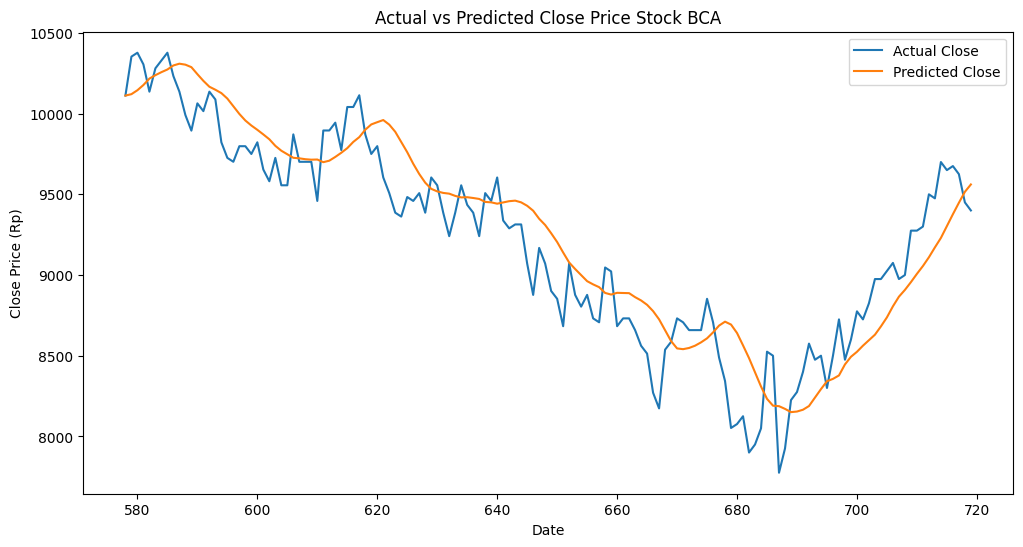

epochs: 30


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 78ms/step - loss: 0.0835 - val_loss: 0.0558
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.0068 - val_loss: 0.0231
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.0053 - val_loss: 0.0071
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - loss: 0.0033 - val_loss: 0.0037
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.0028 - val_loss: 0.0034
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - loss: 0.0025 - val_loss: 0.0018
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - loss: 0.0023 - val_loss: 0.0028
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - loss: 0.0026 - val_loss: 0.0048
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 84ms/step - loss: 0.0025 - val_loss: 0.0017
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step - loss: 0.0023 - val_loss: 0.0017
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 143ms/step
RMSE: 245.97


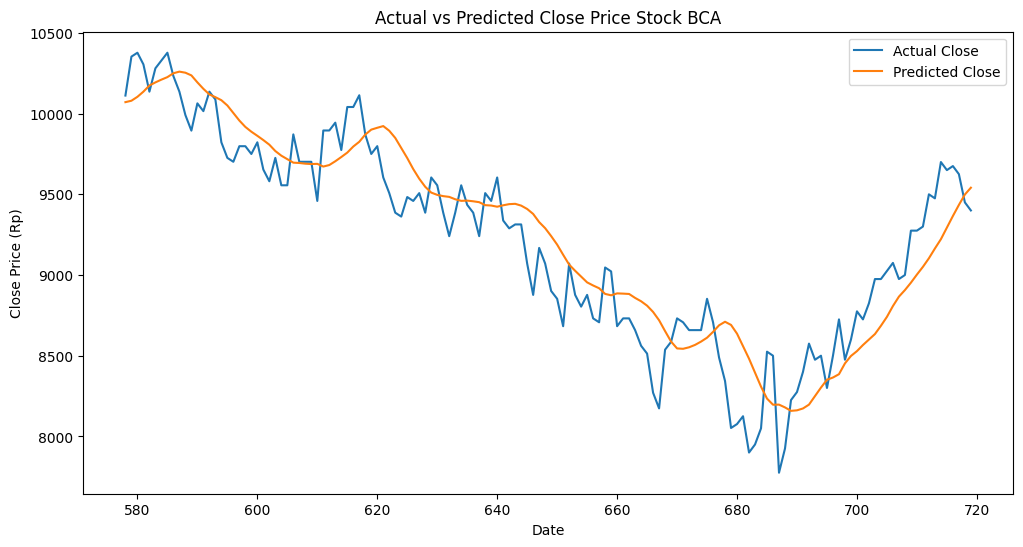

epochs: 20


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 83ms/step - loss: 0.0839 - val_loss: 0.0443
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - loss: 0.0078 - val_loss: 0.0237
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - loss: 0.0045 - val_loss: 0.0074
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - loss: 0.0027 - val_loss: 0.0029
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 87ms/step - loss: 0.0026 - val_loss: 0.0049
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step - loss: 0.0028 - val_loss: 0.0018
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - loss: 0.0024 - val_loss: 0.0017
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.0024 - val_loss: 0.0034
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - loss: 0.0025 - val_loss: 0.0021
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - loss: 0.0030 - val_loss: 0.0018
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step
RMSE: 246.14


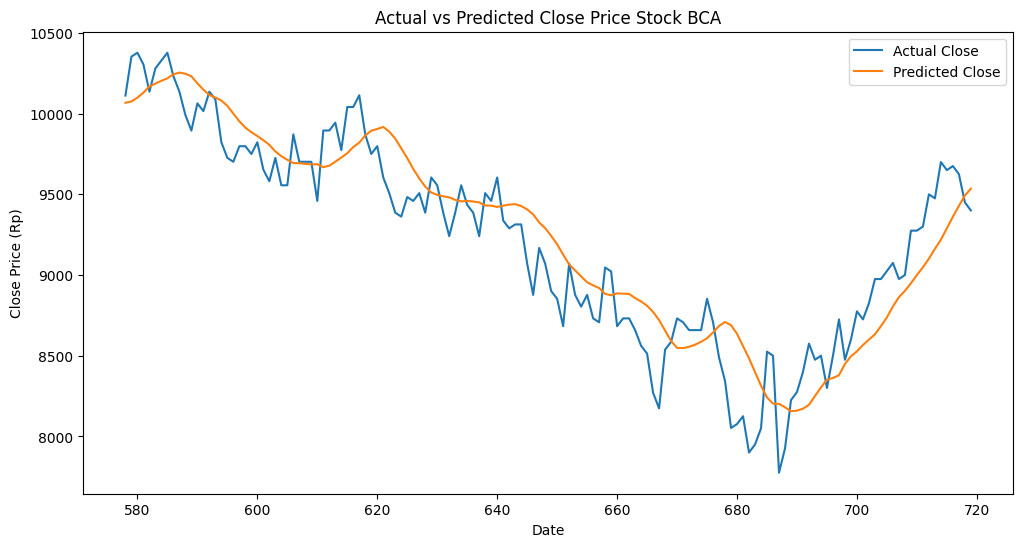

units: 170
dropout: 0.2
epochs: 10
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 97ms/step - loss: 0.0915 - val_loss: 0.0541
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 86ms/step - loss: 0.0084 - val_loss: 0.0247
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - loss: 0.0042 - val_loss: 0.0045
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 0.0030 - val_loss: 0.0018
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 0.0028 - val_loss: 0.0027
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - loss: 0.0025 - val_loss: 0.0027
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - loss: 0.0027 - val_loss: 0.0023
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - loss: 0.0023 - val_loss: 0.0019
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - loss: 0.0025 - val_loss: 0.0020
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - loss: 0.0024 - val_loss: 0.0018
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 104ms/step
RMSE: 265.55


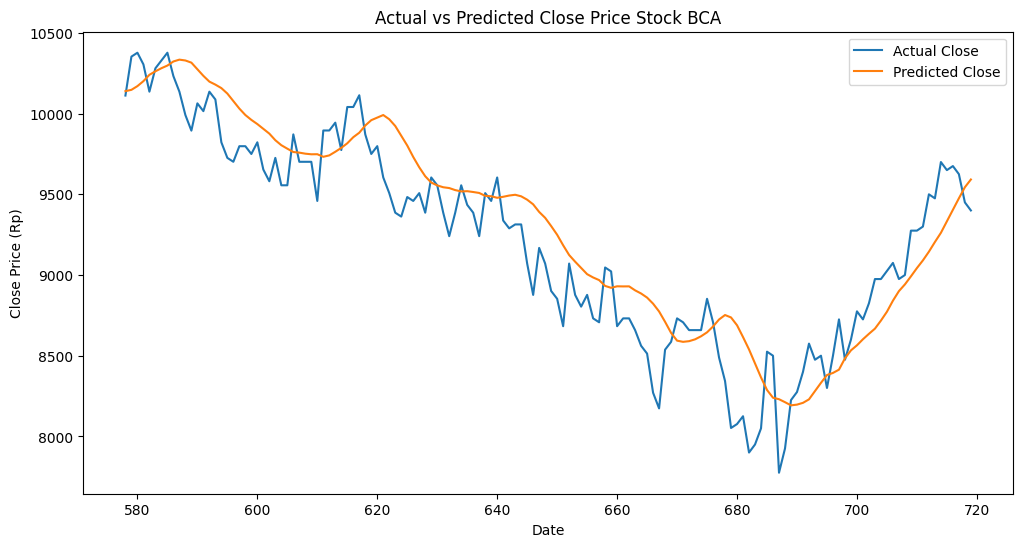

epochs: 30
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 82ms/step - loss: 0.1045 - val_loss: 0.0467
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - loss: 0.0065 - val_loss: 0.0119
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - loss: 0.0029 - val_loss: 0.0034
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - loss: 0.0027 - val_loss: 0.0022
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - loss: 0.0029 - val_loss: 0.0020
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 0.0027 - val_loss: 0.0021
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - loss: 0.0030 - val_loss: 0.0020
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - loss: 0.0025 - val_loss: 0.0018
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step - loss: 0.0027 - val_loss: 0.0024
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 81ms/step - loss: 0.0026 - val_loss: 0.0024
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 103ms/step
RMSE: 249.46


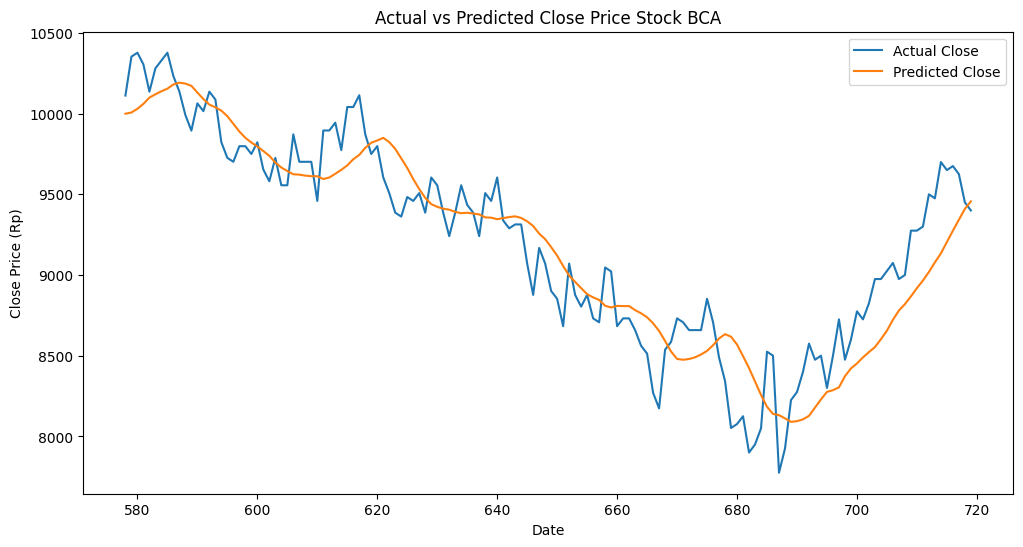

epochs: 20
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 86ms/step - loss: 0.0962 - val_loss: 0.0665
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - loss: 0.0090 - val_loss: 0.0148
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 90ms/step - loss: 0.0037 - val_loss: 0.0043
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - loss: 0.0029 - val_loss: 0.0025
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - loss: 0.0028 - val_loss: 0.0020
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - loss: 0.0026 - val_loss: 0.0022
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - loss: 0.0023 - val_loss: 0.0019
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - loss: 0.0025 - val_loss: 0.0025
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - loss: 0.0024 - val_loss: 0.0018
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - loss: 0.0027 - val_loss: 0.0020
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step
RMSE: 244.82


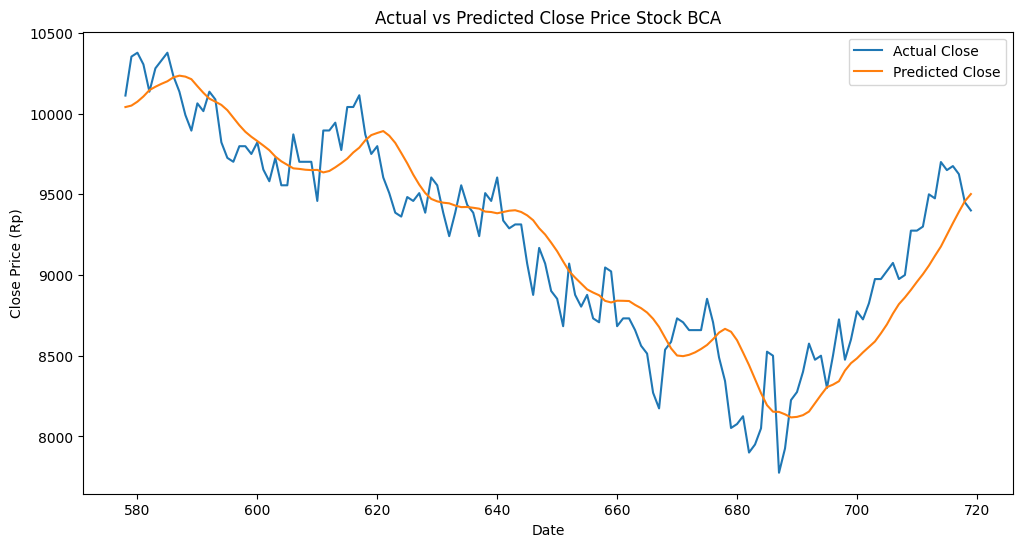

dropout: 0.3
epochs: 10
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 136ms/step - loss: 0.1181 - val_loss: 0.0606
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - loss: 0.0104 - val_loss: 0.0104
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - loss: 0.0039 - val_loss: 0.0040
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - loss: 0.0029 - val_loss: 0.0022
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - loss: 0.0027 - val_loss: 0.0025
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - loss: 0.0027 - val_loss: 0.0018
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - loss: 0.0028 - val_loss: 0.0027
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - loss: 0.0028 - val_loss: 0.0021
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - loss: 0.0027 - val_loss: 0.0024
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - loss: 0.0025 - val_loss: 0.0046
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 163ms/step
RMSE: 345.69


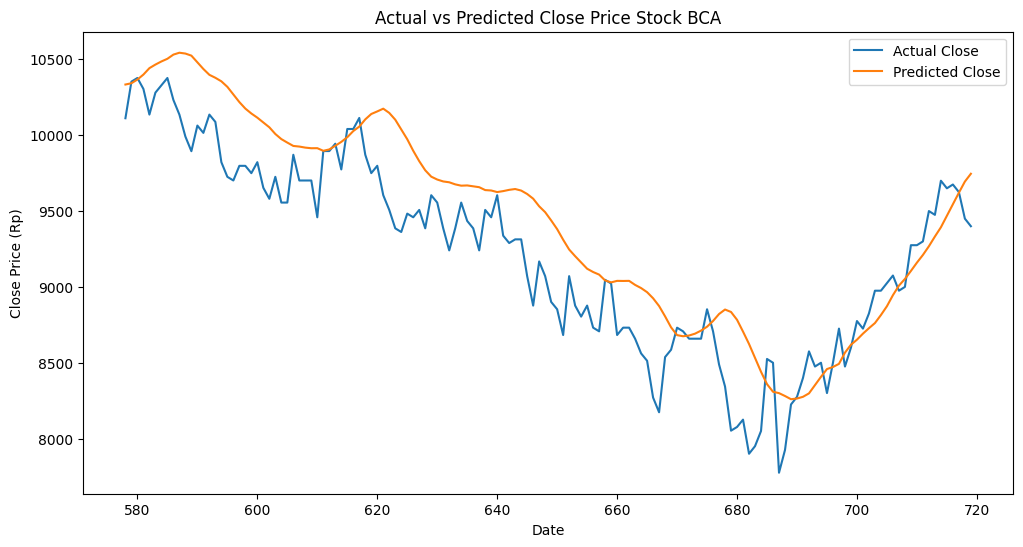

epochs: 30


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 92ms/step - loss: 0.0830 - val_loss: 0.0599
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - loss: 0.0089 - val_loss: 0.0159
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - loss: 0.0039 - val_loss: 0.0063
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - loss: 0.0031 - val_loss: 0.0032
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - loss: 0.0029 - val_loss: 0.0029
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 86ms/step - loss: 0.0031 - val_loss: 0.0024
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 86ms/step - loss: 0.0024 - val_loss: 0.0018
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - loss: 0.0023 - val_loss: 0.0020
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - loss: 0.0023 - val_loss: 0.0019
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - loss: 0.0025 - val_loss: 0.0021
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step
RMSE: 241.11


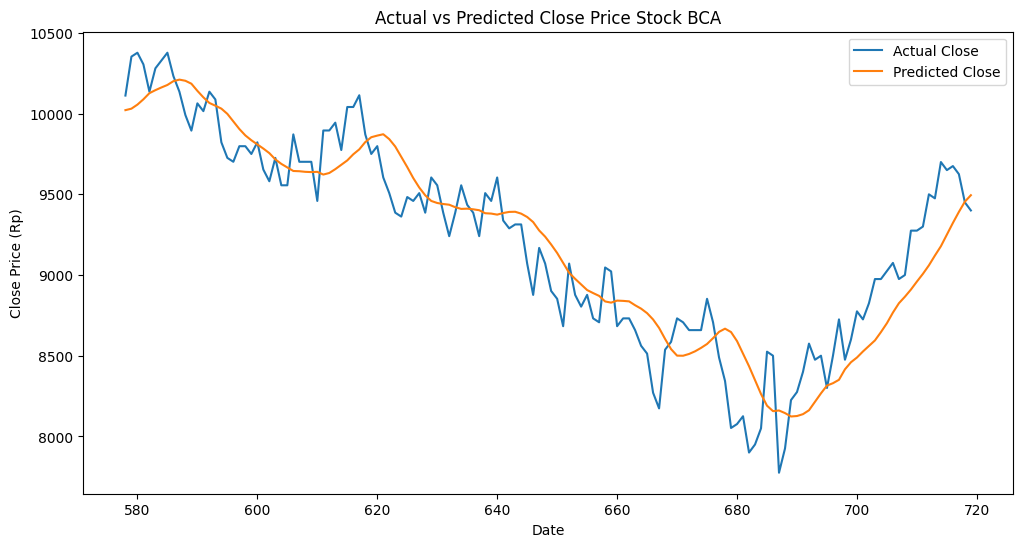

epochs: 20
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step - loss: 0.0909 - val_loss: 0.0427
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 85ms/step - loss: 0.0079 - val_loss: 0.0199
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - loss: 0.0047 - val_loss: 0.0070
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - loss: 0.0029 - val_loss: 0.0028
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - loss: 0.0027 - val_loss: 0.0025
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - loss: 0.0026 - val_loss: 0.0020
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - loss: 0.0026 - val_loss: 0.0019
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - loss: 0.0025 - val_loss: 0.0019
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - loss: 0.0023 - val_loss: 0.0019
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - loss: 0.0026 - val_loss: 0.0022
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step
RMSE: 248.20


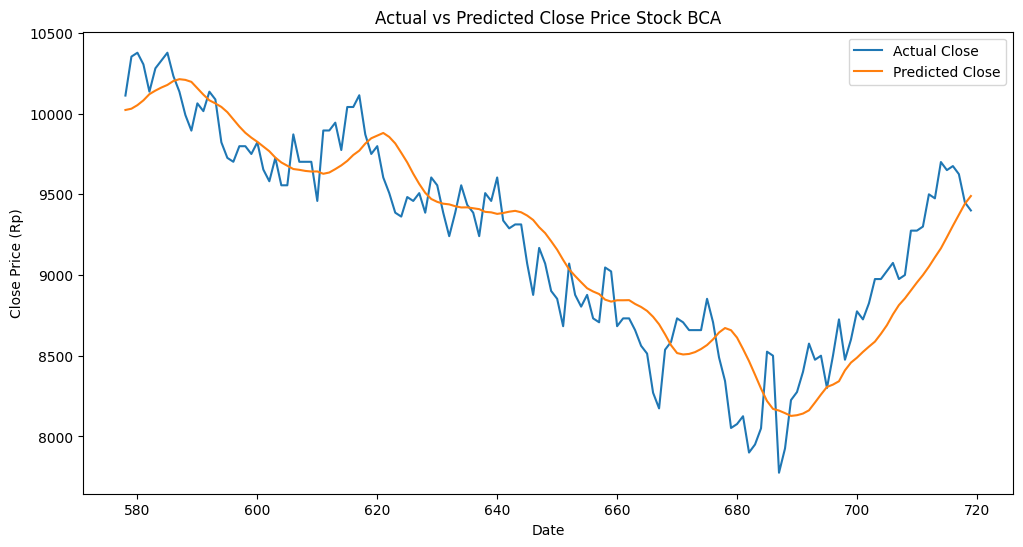

dropout: 0.1
epochs: 10
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 91ms/step - loss: 0.0975 - val_loss: 0.0816
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - loss: 0.0115 - val_loss: 0.0119
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - loss: 0.0049 - val_loss: 0.0032
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 125ms/step - loss: 0.0035 - val_loss: 0.0021
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - loss: 0.0026 - val_loss: 0.0018
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - loss: 0.0026 - val_loss: 0.0021
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 96ms/step - loss: 0.0028 - val_loss: 0.0018
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 185ms/step - loss: 0.0028 - val_loss: 0.0018
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 128ms/step - loss: 0.0026 - val_loss: 0.0026
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - loss: 0.0025 - val_loss: 0.0017
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step
RMSE: 255.12


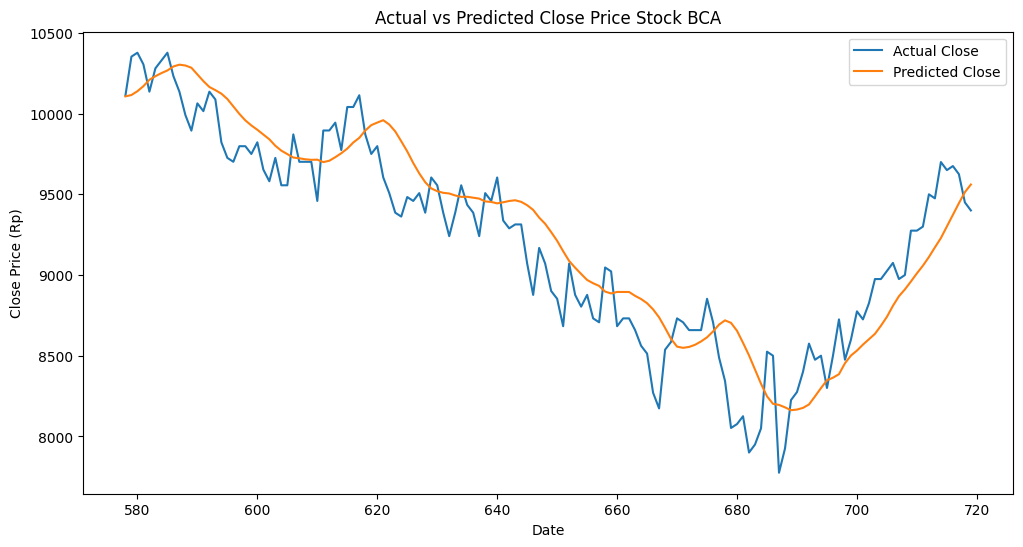

epochs: 30
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 101ms/step - loss: 0.1035 - val_loss: 0.0725
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - loss: 0.0100 - val_loss: 0.0190
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 98ms/step - loss: 0.0051 - val_loss: 0.0048
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 98ms/step - loss: 0.0036 - val_loss: 0.0023
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - loss: 0.0025 - val_loss: 0.0022
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - loss: 0.0024 - val_loss: 0.0018
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - loss: 0.0026 - val_loss: 0.0018
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - loss: 0.0024 - val_loss: 0.0018
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - loss: 0.0022 - val_loss: 0.0019
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - loss: 0.0022 - val_loss: 0.0018
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 119ms/step
RMSE: 248.52


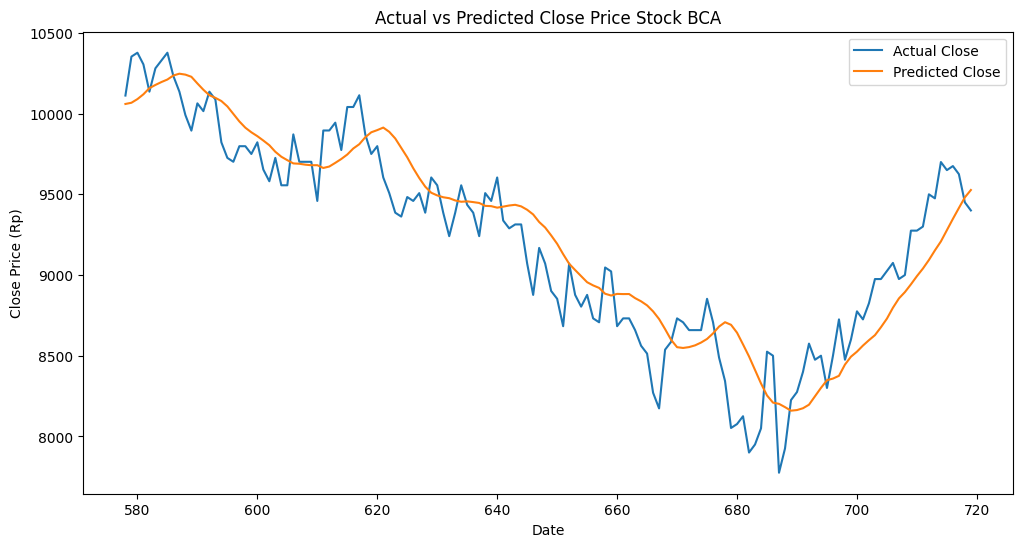

epochs: 20
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - loss: 0.1199 - val_loss: 0.0748
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 66ms/step - loss: 0.0122 - val_loss: 0.0112
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - loss: 0.0045 - val_loss: 0.0022
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - loss: 0.0030 - val_loss: 0.0019
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - loss: 0.0026 - val_loss: 0.0018
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - loss: 0.0024 - val_loss: 0.0021
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - loss: 0.0026 - val_loss: 0.0025
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - loss: 0.0028 - val_loss: 0.0018
Epoch 9/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step - loss: 0.0025 - val_loss: 0.0031
Epoch 10/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 92ms/step - loss: 0.0029 - val_loss: 0.0019
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 111ms/step
RMSE: 248.76


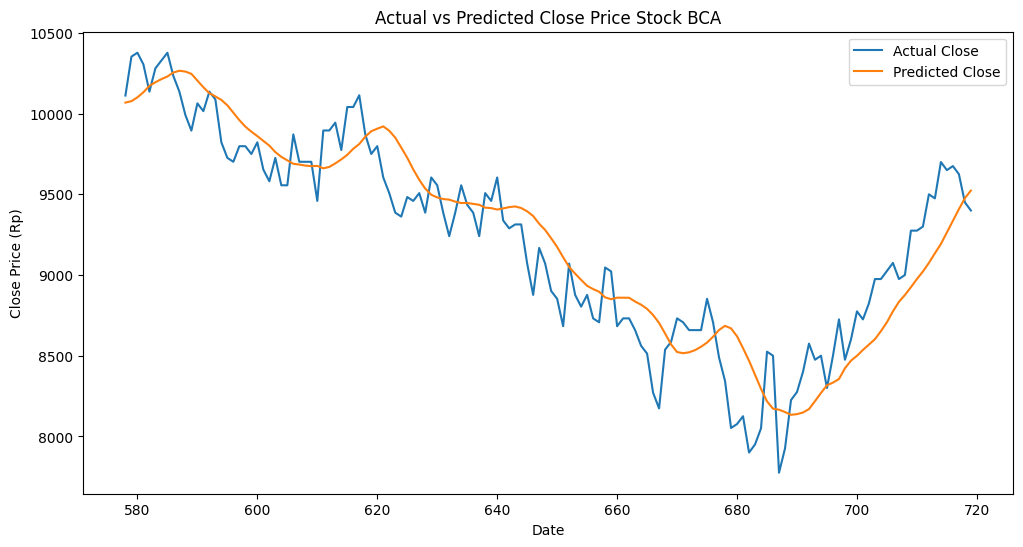

In [ ]:
for i in params['units']:
  print(f'units: {i}')
  for j in params['dropout']:
    print(f'dropout: {j}')
    for k in params['epochs']:
      print(f'epochs: {k}')
      model = Sequential()
      model.add(LSTM(units=128, return_sequences=True, input_shape=(X_train.shape[1], 1)))
      model.add(Dropout(0.2))
      model.add(LSTM(units=128))
      model.add(Dropout(0.2))
      model.add(Dense(1))

      model.compile(optimizer='adam', loss='mean_squared_error')

      history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.1)


      scaler.fit(df[['Close']])

      model_prediksi(model, X_train, y_train, X_test, y_test, scaler, dates_test, epochs=10, batch_size=32)

Hasil tuning hyperparameter memiliki hasil yang beragam namun tidak berbeda jauh namun memiliki pola yang sama untuk tiap pengubahan adalah jumlah epoch tidak harus tinggi tetapi menyesuaikan hasil dari loss dan validation loss, jika penurunan sangat sedikit maka dapat mengambil jumlah epoch yang lossnya berhenti memberikan penurunan yang signifikan. Hal yang hampir serupa untuk dropout yakni jumlah dropout tidak perlu terlalu tinggi atau terlalu rendah tetapi dapat menyesuaikan kebutuhan model sehingga model dapat belajar dengan tidak bergantung dari neuron tertentu dengan jumlah yang tepat.